Over 20 years at Hamburg:

- How much energy does a turbine produce in a typical year (P50)?
- How bad can a weak year be (P90)?
- How strongly does energy depend on wind speed?
- How many years of data do you need for a reliable long-term average?

In [12]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("../src")
import windtools as wt
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/hamburg_hourly.csv", index_col="time", parse_dates=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
df

,u100,v100,ws100,wd100,cf
time,,,,,
2005-01-01 00:00:00,1.432632,-3.665863,3.935859,338.65427,0.019971
2005-01-01 01:00:00,2.352676,-3.432892,4.161710,325.57584,0.026502
2005-01-01 02:00:00,3.060471,-3.228302,4.448417,316.52872,0.035877
2005-01-01 03:00:00,3.404236,-2.763260,4.384567,309.06665,0.033681
2005-01-01 04:00:00,3.749527,-1.756104,4.140393,295.09620,0.025854
...,...,...,...,...,...
2025-12-31 19:00:00,8.112976,-0.184998,8.115085,271.30627,0.298304
2025-12-31 20:00:00,8.281708,1.091125,8.353277,262.49445,0.326789
2025-12-31 21:00:00,8.368317,1.911346,8.583820,257.13420,0.355951


# Annual Table

In [3]:
# Why 5 MW? It’s just an assumed turbine size, roughly typical for a 
# modern onshore turbine (about 4–6 MW). 
# You could equally pick 3 MW or 100 MW for a small wind farm.
rated_mw = 5 

In [4]:
annual_table = df.groupby(df.index.year).agg(
    mean_ws=("ws100", "mean"),
    cf=("cf", "mean"),
)
annual_table.index.name = "year"

#energy_gwh = cf × 5 MW × 8760 h / 1000

annual_table["energy_gwh"] = annual_table["cf"] * rated_mw * 8760 / 1000

annual_table.round(2)

,mean_ws,cf,energy_gwh
year,,,
2005,6.27,0.20,8.75
2006,6.23,0.20,8.86
2007,6.65,0.24,10.52
2008,6.61,0.23,10.21
2009,6.28,0.20,8.67
2010,6.09,0.19,8.17
2011,6.62,0.24,10.32
2012,6.42,0.21,9.24
2013,6.26,0.20,8.77


# P50 and P90 Annual Energy

P50 is the mean annual energy across the years in the dataset. The sample standard deviation (`ddof=1`) measures year-to-year variability. The standard deviation expressed as a percentage of P50 is:

$$
\sigma_{\%P50} = 100\frac{\sigma}{P50}
$$

P90 is estimated from P50 and the sample standard deviation. For a single-year estimate:

$$
P90_{1\text{ year}} = P50 - 1.282\sigma
$$

For the average across 10 years:

$$
P90_{10\text{ years}} = P50 - \frac{1.282\sigma}{\sqrt{10}}
$$

The notebook reports both P90 estimates in GWh and as a percentage of P50, calculated as $100\times P90/P50$. These estimates use the annual energy values in the table and the assumed 5 MW turbine.

10-year $\sigma$ = annual $\sigma$ / $\sqrt{10}$, assuming independent years

In [8]:
p_one_year = wt.p_values(annual_table["energy_gwh"], horizon_years=1)
p_ten_years = wt.p_values(annual_table["energy_gwh"], horizon_years=10)

p_summary = pd.DataFrame({
    "1-year estimate": p_one_year,
    "10-year estimate": p_ten_years,
})
p_summary.index = [
    "P50 (GWh)",
    "σ of the mean over the horizon (GWh)",
    "σ (% of P50)",
    "P90 (GWh)",
    "P90 (% of P50)",
]
p_summary.round(2)

,1-year estimate,10-year estimate
P50 (GWh),9.25,9.25
σ of the mean over the horizon (GWh),0.81,0.26
σ (% of P50),8.73,2.76
P90 (GWh),8.21,8.92
P90 (% of P50),88.80,96.46


# Is the normal assumption reasonable?

Why: the 1.282 in the P90 formula comes from the normal distribution. If annual energy isn’t roughly normal, the formula-based P90 could be wrong.

If the points lie close to the straight line, the data is approximately normal. Points bending away at the ends mean the tails differ from a normal distribution.

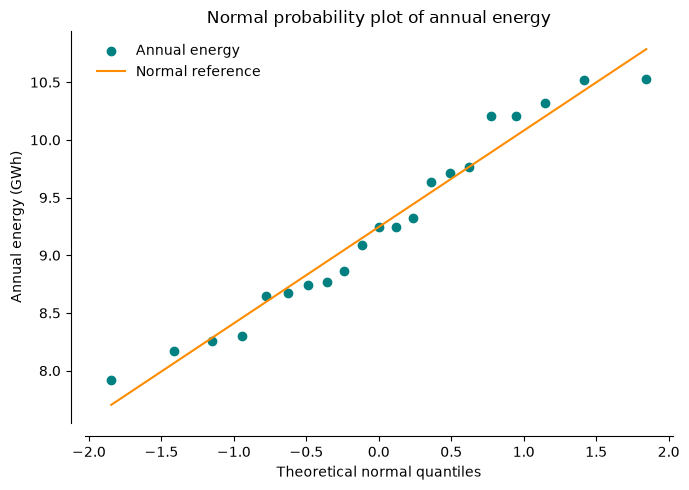

In [19]:
(osm, osr), (slope, intercept, r) = stats.probplot(
    annual_table["energy_gwh"], dist="norm"
)

fig, ax = plt.subplots(figsize=(7, 5))
ax.spines.left.set_position(('outward', 10))
ax.spines.bottom.set_position(('outward', 10))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.scatter(osm, osr, color="teal", label="Annual energy")
x = np.array([osm.min(), osm.max()])
ax.plot(x, slope * x + intercept, color="darkorange", label="Normal reference")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set(
    title="Normal probability plot of annual energy",
    xlabel="Theoretical normal quantiles",
    ylabel="Annual energy (GWh)",
)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

In [24]:
p90_empirical = np.percentile(annual_table["energy_gwh"], 10)
print(round(p90_empirical, 2), "GWh is the empirical P90 of annual energy")

8.25 GWh is the empirical P90 of annual energy


The Q–Q plot shows the annual energy values close to the normal reference line. The empirical P90 (10th percentile of annual energy, 8.25 GWh) agrees with the normal-based P90 (8.21 GWh) within 0.5% of P50. The normal assumption is therefore reasonable for this dataset, although with only 20 years the tails of the distribution are poorly constrained.

# Bar chart of annual energy

It shows year-to-year variability at a glance. 

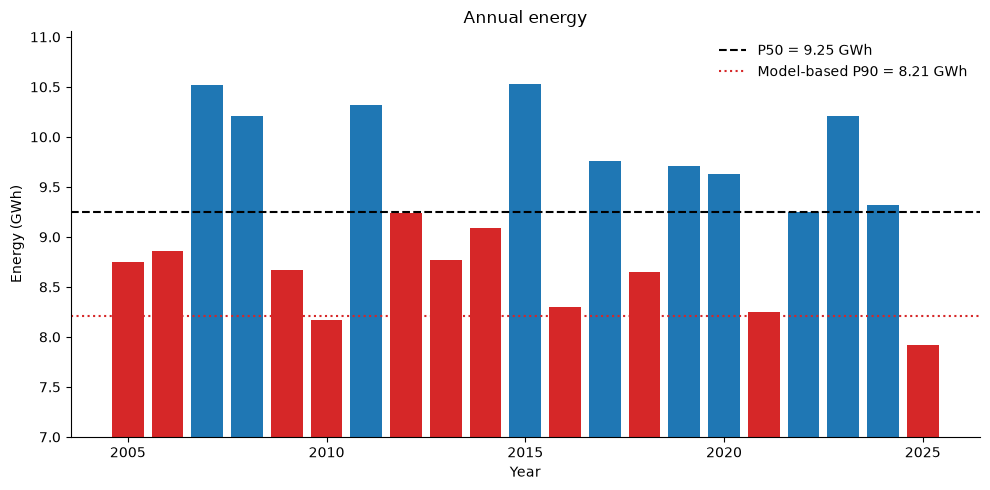

In [33]:
p50 = annual_table["energy_gwh"].mean()
p90_1y = p_summary.loc["P90 (GWh)", "1-year estimate"]
colors = np.where(annual_table["energy_gwh"] >= p50, "tab:blue", "tab:red")

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(annual_table.index, annual_table["energy_gwh"], color=colors)
ax.axhline(p50, color="black", linestyle="--", label=f"P50 = {p50:.2f} GWh")
ax.axhline(p90_1y, color="tab:red", linestyle=":", label=f"Model-based P90 = {p90_1y:.2f} GWh")
ax.set(
    title="Annual energy",
    xlabel="Year",
    ylabel="Energy (GWh)",
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylim(7, None)
ax.legend(frameon=False)
fig.tight_layout()
plt.savefig("../figures/annual_energy.png", dpi=150, bbox_inches="tight")

In [34]:
energy = annual_table["energy_gwh"]
p50 = energy.mean()
p90_1y = p_summary.loc["P90 (GWh)", "1-year estimate"]

best, worst = energy.idxmax(), energy.idxmin()
best_pct = (energy.loc[best] / p50 - 1) * 100
worst_pct = (1 - energy.loc[worst] / p50) * 100
below_p90 = (energy < p90_1y).sum()

print(
    f"The strongest year was {best} (+{best_pct:.1f}% vs P50), "
    f"the weakest {worst} (−{worst_pct:.1f}%); "
    f"{below_p90} of {len(energy)} years fell below the 1-year P90."
)

The strongest year was 2015 (+13.9% vs P50), the weakest 2025 (−14.3%); 2 of 21 years fell below the 1-year P90.


# How sensitive is energy to wind speed?

Why: a turbine’s output depends strongly on wind speed. This cell measures how strongly at the annual scale. It matters in practice: if a wind speed estimate is 2% too high, how wrong is the energy estimate?

The concept: elasticity. Elasticity = % change in energy for a 1% change in wind speed. You get it as the slope of a straight line fitted in log–log space, because a power law $E ∝ v^b$ becomes a straight line there: log $E = b · log v + const$. The slope b is the elasticity.

What to expect: $power ∝ v³$ in theory, but you’ll find a smaller value, typically around 2–3. Part of the time the turbine is either standing still (below cut-in) or at full power (above rated). There, small changes in wind speed don’t change the output.

Elasticity (slope): 2.99
Correlation in log-log space: r = 0.975
-> 1% more wind speed gives about 3.0% more energy


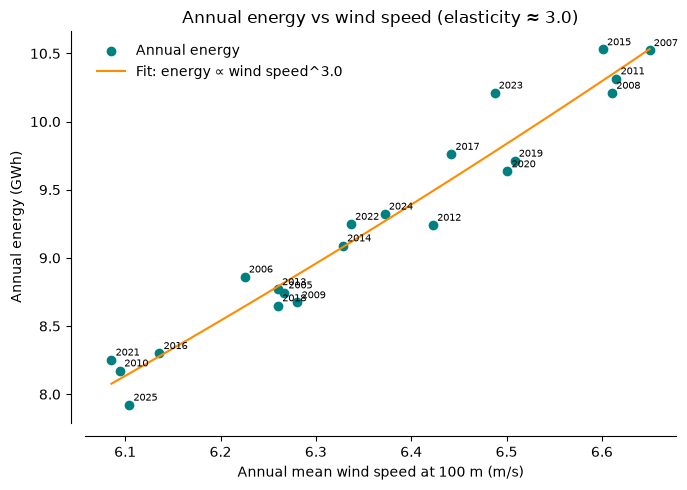

In [38]:
# 1. Fit a straight line in log-log space: log(E) = slope * log(ws) + intercept
log_ws = np.log(annual_table["mean_ws"])
log_e = np.log(annual_table["energy_gwh"])
slope, intercept = np.polyfit(log_ws, log_e, 1)
r = np.corrcoef(log_ws, log_e)[0, 1]          # how well the line fits

print(f"Elasticity (slope): {slope:.2f}")
print(f"Correlation in log-log space: r = {r:.3f}")
print(f"-> 1% more wind speed gives about {slope:.1f}% more energy")

# 2. Scatter plot of the 20 years
# ...existing code...
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(
    annual_table["mean_ws"],
    annual_table["energy_gwh"],
    color="teal",
    label="Annual energy",
)

for year, row in annual_table.iterrows():
    ax.annotate(
        str(year),
        (row["mean_ws"], row["energy_gwh"]),
        fontsize=7,
        xytext=(3, 3),
        textcoords="offset points",
    )

ws_line = np.linspace(
    annual_table["mean_ws"].min(),
    annual_table["mean_ws"].max(),
    50,
)
ax.plot(
    ws_line,
    np.exp(intercept) * ws_line**slope,
    color="darkorange",
    lw=1.5,
    label=f"Fit: energy ∝ wind speed^{slope:.1f}",
)

ax.set(
    title=f"Annual energy vs wind speed (elasticity ≈ {slope:.1f})",
    xlabel="Annual mean wind speed at 100 m (m/s)",
    ylabel="Annual energy (GWh)",
)
ax.spines.left.set_position(('outward', 10))
ax.spines.bottom.set_position(('outward', 10))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()

plt.savefig("../figures/energy_vs_windspeed.png", dpi=150, bbox_inches="tight")
plt.show()

Annual energy scales with annual mean wind speed with an elasticity of about 3.0 (r = 0.975 in log–log space): a 1% increase in mean wind speed gives about 3% more energy. This close-to-cubic response reflects the low-wind character of the site (mean capacity factor ~21%), where the turbine operates mostly in the partial-load region of its power curve rather than at rated power. Practical consequence: a 0.5 m/s low bias in ERA5 onshore wind speed (~7%) would underestimate annual energy by roughly 20%.

# Monthly capacity factor


Why: annual values hide the seasonal cycle. This shows which months produce most of the energy, and how much a single month varies between years. That matters for monthly cash flow and short-term planning.

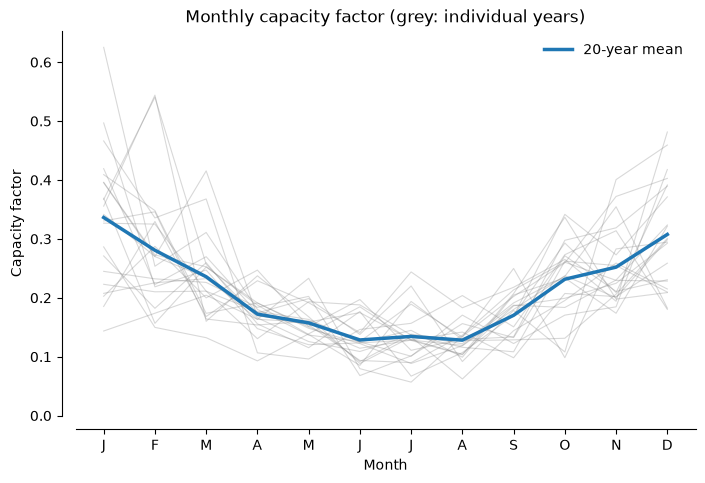

Year-to-year variability per month (% of mean):
time
1     34.6
2     37.8
3     28.7
4     21.7
5     20.8
6     29.7
7     34.9
8     24.8
9     23.5
10    29.0
11    26.1
12    29.8
dtype: float64

Year-to-year variability of annual CF: 8.7%


In [42]:
# Monthly mean CF: rows = years, columns = months (1-12)
monthly = df["cf"].groupby([df.index.year, df.index.month]).mean().unstack()

fig, ax = plt.subplots(figsize=(8, 5))

# One thin grey line per year
for year in monthly.index:
    ax.plot(monthly.columns, monthly.loc[year], color="grey", alpha=0.3, lw=0.8)

# Mean seasonal cycle
ax.plot(monthly.columns, monthly.mean(), color="tab:blue", lw=2.5, label="20-year mean")

ax.set_xticks(range(1, 13))
ax.set_xticklabels(["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_xlabel("Month")
ax.set_ylabel("Capacity factor")
ax.set_title("Monthly capacity factor (grey: individual years)")
ax.legend()
ax.set_ylim(0, None)
ax.spines.left.set_position(('outward', 10))
ax.spines.bottom.set_position(('outward', 10))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

plt.savefig("../figures/monthly_cf.png", dpi=150, bbox_inches="tight")
plt.show()

# Compare variability: single months vs whole years
monthly_cv = (monthly.std() / monthly.mean() * 100).round(1)   # % variability per month
annual_cv = annual_table["cf"].std() / annual_table["cf"].mean() * 100
print("Year-to-year variability per month (% of mean):")
print(monthly_cv)
print(f"\nYear-to-year variability of annual CF: {annual_cv:.1f}%")

Mean capacity factor follows a clear seasonal cycle: highest in winter (January ≈ 0.34) and lowest in summer (June–August ≈ 0.13), consistent with the stronger North Atlantic storm track in winter and with the summer peak of low-wind events found in notebook 1. Year-to-year variability of individual months (21–38% of the monthly mean) is far larger than that of annual totals (8.7%), because annual means average over many weather systems. Winter months are both the most productive and among the most variable (February 38%), while spring months are the most consistent (May 21%). The high relative variability in July partly reflects the small summer mean.

# How many years of data do we need?

If we measure wind at a site for 1 year, how far could that year’s mean be from the true long-term mean? This cell answers it with the data. It’s the reason industry corrects short on-site measurements with long-term reanalysis.

In [43]:
p50 = annual_table["energy_gwh"].mean()
sigma = annual_table["energy_gwh"].std(ddof=1)
n_years = len(annual_table)

results = []
for w in range(1, n_years + 1):
    # all possible w-year averages (rolling windows)
    window_means = annual_table["energy_gwh"].rolling(w).mean().dropna()
    results.append({
        "years": w,
        "n_windows": len(window_means),
        "spread_pct": (window_means.max() - window_means.min()) / p50 * 100,
        "std_pct": window_means.std(ddof=1) / p50 * 100 if len(window_means) > 1 else np.nan,
    })
conv = pd.DataFrame(results)
print(conv.round(2))

# Theory if years were independent: sigma / sqrt(w)
theory_pct = sigma / np.sqrt(conv["years"]) / p50 * 100


    years  n_windows  spread_pct  std_pct
0       1         21       28.20     8.73
1       2         20       21.02     5.31
2       3         19       10.39     2.84
3       4         18        5.65     1.70
4       5         17        6.46     1.83
5       6         16        5.18     1.55
6       7         15        3.78     1.13
7       8         14        2.77     0.88
8       9         13        3.39     0.99
9      10         12        3.64     1.15
10     11         11        2.36     0.76
11     12         10        1.82     0.57
12     13          9        2.37     0.85
13     14          8        2.50     0.89
14     15          7        1.36     0.50
15     16          6        1.39     0.54
16     17          5        2.22     0.81
17     18          4        1.56     0.73
18     19          3        0.53     0.27
19     20          2        0.45     0.31
20     21          1        0.00      NaN


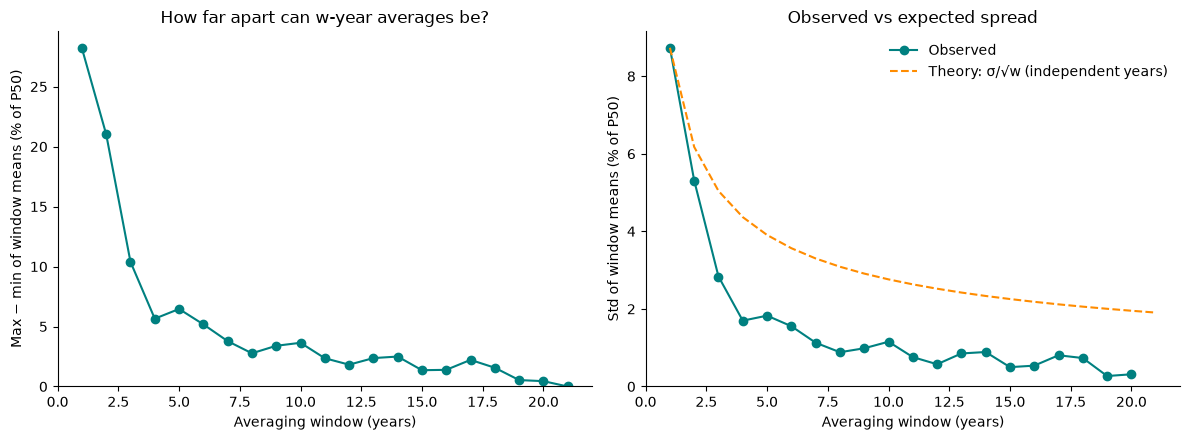

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: range of all w-year means
axes[0].plot(
    conv["years"],
    conv["spread_pct"],
    marker="o",
    color="teal",
)
axes[0].set(
    xlabel="Averaging window (years)",
    ylabel="Max − min of window means (% of P50)",
    title="How far apart can w-year averages be?",
)

# Right: observed standard deviation vs independent-years theory
axes[1].plot(
    conv["years"],
    conv["std_pct"],
    marker="o",
    color="teal",
    label="Observed",
)
axes[1].plot(
    conv["years"],
    theory_pct,
    linestyle="--",
    color="darkorange",
    label="Theory: σ/√w (independent years)",
)
axes[1].set(
    xlabel="Averaging window (years)",
    ylabel="Std of window means (% of P50)",
    title="Observed vs expected spread",
)
axes[1].legend(frameon=False)

# Make both sets of axes cross at (0, 0)
for ax in axes:
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.spines["left"].set_position(("data", 0))
    ax.spines["bottom"].set_position(("data", 0))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.tight_layout()
plt.savefig("../figures/convergence.png", dpi=150, bbox_inches="tight")
plt.show()

In [52]:
r1 = annual_table["energy_gwh"].autocorr(lag=1)
print(np.round(r1, 2))

-0.24


With a single year of data, annual yield can differ by up to 28% of P50 between the best and worst year; averaging over 3–4 years reduces this to below 10%, and over a decade to about 4%. This illustrates why short on-site measurement campaigns must be placed in a long-term context. The standard deviation of overlapping w-year means falls faster than the independent-years expectation σ/√w, largely because overlapping windows share most of their years. The lag-1 autocorrelation of annual energy is weak and not statistically significant (r = −0.24; with 21 years, |r| would need to exceed about 0.43). Consecutive years are therefore approximately independent, so the √10 assumption behind the 10-year P90 is justified, and if anything slightly conservative

# Is there a trend?

If annual capacity factor were steadily rising or falling, a P50 based on the past 21 years would be biased for future years. This checks for that.

Trend: -0.0034 CF per decade
Relative trend: -1.6% of mean CF per decade
p-value: 0.62


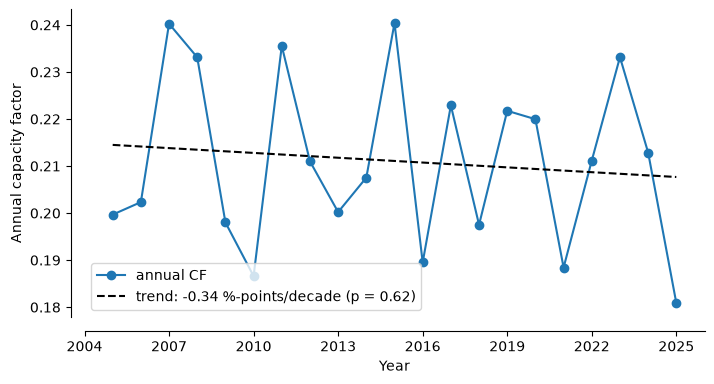

In [57]:
from scipy import stats

res = stats.linregress(annual_table.index, annual_table["cf"])

print(f"Trend: {res.slope * 10:.4f} CF per decade")
print(f"Relative trend: {res.slope * 10 / annual_table['cf'].mean() * 100:.1f}% of mean CF per decade")
print(f"p-value: {res.pvalue:.2f}")

from matplotlib.ticker import MaxNLocator
fig, ax = plt.subplots(figsize=(8, 4))
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.spines.left.set_position(('outward', 10))
ax.spines.bottom.set_position(('outward', 10))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.plot(annual_table.index, annual_table["cf"], "o-", label="annual CF")
ax.plot(annual_table.index, res.intercept + res.slope * annual_table.index, "k--",
        label=f"trend: {res.slope * 10 * 100:+.2f} %-points/decade (p = {res.pvalue:.2f})")
ax.set_xlabel("Year")
ax.set_ylabel("Annual capacity factor")
ax.legend()
plt.savefig("../figures/cf_trend.png", dpi=150, bbox_inches="tight")
plt.show()

Annual capacity factor shows no significant trend over 2005–2025 (−1.6% of the mean per decade, p = 0.62), small compared with the year-to-year variability (8.7%). Using the 21-year mean as P50 is therefore reasonable. Note that 21 years is short: multi-decadal variability such as the North Atlantic Oscillation can produce or mask trends on this timescale.

# Key findings

**Typical yield and variability:** A generic 5 MW turbine at Hamburg would produce about 9.25 GWh per year (P50, capacity factor ≈ 21%). Individual years scatter by ±8.7%, and the best and worst years differ by 28% of P50.

**P90:** In 9 out of 10 years, output exceeds 8.21 GWh (89% of P50). Averaged over 10 years, the P90 rises to 8.92 GWh (96% of P50), because strong and weak years cancel out. The normal-distribution assumption is supported by the data (empirical P90 = 8.25 GWh).

**Sensitivity to wind speed:** 1% more mean wind speed gives about 3% more energy (elasticity 3.0, r = 0.975), so small wind speed errors strongly affect yield estimates.

**Seasonality:** Capacity factor is highest in winter (January ≈ 0.34) and lowest in summer (June–August ≈ 0.13). Single months vary by 21–38% from year to year.

**Data length:** A single year can misrepresent the long-term yield by up to ~28%; 3–4 years reduce this to below 10%, and a decade to ~4%. Consecutive years are approximately independent (r = −0.24), and there is no significant trend over 2005–2025.

# Limitations

P90 includes only interannual variability. Real energy yield assessments also include measurement, modelling, and loss uncertainties, which lower P90 further.

Normal distribution and independent years are assumed; both are supported here but tested with only 21 years.

ERA5 resolution (~30 km) smooths local terrain and tends to underestimate onshore wind speeds. Given the elasticity of ~3, absolute yields are indicative only; relative results (σ, P90/P50) are more robust.

Generic power curve: no air-density correction, wake, availability, or curtailment losses.

Overlapping windows in the convergence analysis are not independent samples, so their standard deviations are biased low.